imports

In [38]:
import sys, os, re, json, random
sys.path.append("../src")
import numpy as np, pandas as pd, ollama, chromadb
import matplotlib.pyplot as plt
from tqdm import tqdm
from llm_utils import *

random.seed(42); np.random.seed(42)
os.makedirs("../results", exist_ok=True)
dev   = pd.read_csv("../data/po_dev.csv")
train = pd.read_csv("../data/po_train.csv")
print(len(dev), "dev |", len(train), "train")

498 dev | 3517 train


policy

In [2]:
POLICY_MD = """# Segregation of Duties Policy (synthetic company policy)

## Purpose and Scope
This policy governs the purchase-to-pay process. Every purchase order (PO) passes through five steps: creation, approval, goods receipt, invoice posting and payment posting. The aim is that no single person controls enough of this chain to commit and hide an error or fraud. Each step should be handled by an appropriate person.

## Roles and Permissions
PO_CREATOR may create purchase orders. PO_APPROVER may approve purchase orders. WAREHOUSE posts goods receipts. AP_CLERK posts supplier invoices. PAYMENT_PROCESSOR posts payments. VENDOR_ADMIN creates and maintains vendor master records.

## Access Risk Versus Violation
A user who holds two conflicting roles, for example PO_CREATOR together with PAYMENT_PROCESSOR, represents an access risk that should be reported for role clean-up. Holding conflicting roles is NOT a violation of a purchase order by itself. A violation exists only when the conflicting access was actually used on the same PO or the same vendor. When reviewing a PO, compare the user ids in each step. Do not flag a PO merely because one of the users holds conflicting roles.

## Rule R1 SOD_CREATE_PAY: Creator Must Not Pay
The user who created a purchase order must not post the payment for that same purchase order. If the user id on the Created step is identical to the user id on the Payment posted step, the PO violates rule R1 and the violation type is SOD_CREATE_PAY. If the two user ids are different, rule R1 is satisfied.

## Rule R2 SELF_APPROVAL: Creator Must Not Approve
The user who created a purchase order must not approve it. If the user id on the Created step is identical to the user id on the Approved step, the PO violates rule R2 and the violation type is SELF_APPROVAL. If the two user ids are different, rule R2 is satisfied.

## Rule R3 VENDOR_CREATE_PAY: Vendor Creator Must Not Pay That Vendor
The user who created a vendor record must not post payments to that vendor. If the user who created the vendor, shown in the context line, is the same user who posted the payment, the PO violates rule R3 and the violation type is VENDOR_CREATE_PAY.

## Rule R4 MISSING_APPROVAL: Approval Is Mandatory
Every purchase order must have an Approved step before payment is posted. If the list of steps contains no Approved step, the PO violates rule R4 and the violation type is MISSING_APPROVAL, even when every other step looks normal. Count the steps carefully: a normal PO has five steps, and a PO with only four steps and no approval is a violation.

## Rule R5 SPLIT_BELOW_THRESHOLD: Splitting Payments
The approval limit is INR 50,000. Splitting one purchase into several smaller ones to stay under the limit is prohibited. Flag a PO as SPLIT_BELOW_THRESHOLD only when the context line shows three or more other POs by the same creator to the same vendor within 7 days AND the amount is within 10 percent below the limit, that is between INR 45,000 and INR 49,999. A single PO near the limit, or only one or two other POs, is not enough to flag.

## Review Procedure
Step 1: list the user at each step. Step 2: check rules R1, R2 and R3 by comparing user ids; identical ids mean a violation. Step 3: check rule R4 by confirming an Approved step exists. Step 4: check rule R5 using the context line. Step 5: if no rule is broken, the violation type is NONE.

## Reporting
State the answer as JSON with a short reason that names the rule and the users involved, a violation flag, and the violation type code. Use NONE when the PO complies with the policy.
"""
with open("../data/sod_policy.md", "w", encoding="utf-8") as f:
    f.write(POLICY_MD)

embedding helper and chunk

In [3]:
EMB = "nomic-embed-text"

def embed(texts, prefix="", batch=32):
    out = []
    for i in range(0, len(texts), batch):
        r = ollama.embed(model=EMB, input=[prefix + t for t in texts[i:i+batch]])
        out += r["embeddings"]
    return out

sections = [s.strip() for s in re.split(r"\n(?=## )", POLICY_MD) if s.strip().startswith("## ")]
chunk_title = [s.split("\n")[0][3:] for s in sections]
chunk_type  = [(re.search(r"\b([A-Z]+_[A-Z_]+)\b", t.split(":")[0]) or [None, None])[1] for t in chunk_title]
print(len(sections), "chunks")
for t, ty in zip(chunk_title, chunk_type): print(f"  {t[:60]:60s} -> {ty}")

10 chunks
  Purpose and Scope                                            -> None
  Roles and Permissions                                        -> None
  Access Risk Versus Violation                                 -> None
  Rule R1 SOD_CREATE_PAY: Creator Must Not Pay                 -> SOD_CREATE_PAY
  Rule R2 SELF_APPROVAL: Creator Must Not Approve              -> SELF_APPROVAL
  Rule R3 VENDOR_CREATE_PAY: Vendor Creator Must Not Pay That  -> VENDOR_CREATE_PAY
  Rule R4 MISSING_APPROVAL: Approval Is Mandatory              -> MISSING_APPROVAL
  Rule R5 SPLIT_BELOW_THRESHOLD: Splitting Payments            -> SPLIT_BELOW_THRESHOLD
  Review Procedure                                             -> None
  Reporting                                                    -> None


store in the vector database

In [4]:
client = chromadb.PersistentClient(path="../vectordb")
try: client.delete_collection("policy")
except Exception: pass
col = client.create_collection("policy", metadata={"hnsw:space": "cosine"})

col.add(ids=[f"c{i}" for i in range(len(sections))],
        documents=sections,
        embeddings=embed(sections, prefix="search_document: "),
        metadatas=[{"title": t, "type": str(ty)} for t, ty in zip(chunk_title, chunk_type)])
print("stored", col.count(), "chunks")

stored 10 chunks


trial queries

In [5]:
def retrieve(query, k=3):
    q = embed([query], prefix="search_query: ")[0]
    r = col.query(query_embeddings=[q], n_results=k)
    return r["documents"][0], [m["title"] for m in r["metadatas"][0]], r["distances"][0]

for q in ["same person created and paid the order",
          "payment posted with no approval step",
          "many small payments just under the limit"]:
    print(q, "->", retrieve(q)[1])

same person created and paid the order -> ['Rule R1 SOD_CREATE_PAY: Creator Must Not Pay', 'Rule R3 VENDOR_CREATE_PAY: Vendor Creator Must Not Pay That Vendor', 'Rule R2 SELF_APPROVAL: Creator Must Not Approve']
payment posted with no approval step -> ['Rule R4 MISSING_APPROVAL: Approval Is Mandatory', 'Rule R2 SELF_APPROVAL: Creator Must Not Approve', 'Rule R1 SOD_CREATE_PAY: Creator Must Not Pay']
many small payments just under the limit -> ['Rule R5 SPLIT_BELOW_THRESHOLD: Splitting Payments', 'Rule R1 SOD_CREATE_PAY: Creator Must Not Pay', 'Rule R4 MISSING_APPROVAL: Approval Is Mandatory']


normalize and run retrieval for every dev PO

In [6]:
def normalise(s):
    s = re.sub(r"PO PO-\d+ \| vendor V\d+ \| ", "", s)
    s = re.sub(r" on \d{4}-\d{2}-\d{2} \d{2}:\d{2}", "", s)
    s = re.sub(r"\bV\d{3}\b", "VENDOR", s)
    s = re.sub(r"\bU\d{3}\b", "USER", s)
    return s

print(normalise(dev.summary.iloc[0]))   # check what the query text looks like

K = 3
dev_q = embed([normalise(s) for s in dev.summary], prefix="search_query: ")
hits = col.query(query_embeddings=dev_q, n_results=K)
RETR = {po: "\n\n".join(docs) for po, docs in zip(dev.po_number, hits["documents"])}
RETR_TYPES = {po: [m["type"] for m in metas] for po, metas in zip(dev.po_number, hits["metadatas"])}

amount INR 35,690
1. Created by USER (roles: PO_CREATOR)
2. Approved by USER (roles: PO_APPROVER)
3. Goods received by USER (roles: WAREHOUSE)
4. Invoice posted by USER (roles: AP_CLERK)
5. Payment posted by USER (roles: PAYMENT_PROCESSOR)
Context: vendor VENDOR was created by USER. Other POs by the same creator to this vendor within 7 days: 0. Amount within 10% below the INR 50,000 limit: no.


hit @k per violation type

In [7]:
v = dev[dev.label == "violation"].copy()
v["hit"] = [row.violation_type in RETR_TYPES[row.po_number] for row in v.itertuples()]
rule_chunks = sum(1 for t in chunk_type if t)
print(v.groupby("violation_type")["hit"].agg(["mean", "size"]).round(2))
print(f"overall hit@{K}: {v.hit.mean():.2f} | chance level if random: ~{K/len(sections):.2f}")

                       mean  size
violation_type                   
MISSING_APPROVAL        0.0     9
SELF_APPROVAL           0.0     9
SOD_CREATE_PAY          0.0     9
SPLIT_BELOW_THRESHOLD   1.0     4
VENDOR_CREATE_PAY       1.0     7
overall hit@3: 0.29 | chance level if random: ~0.30


prompt and evidence check

In [ ]:
MINIMAL = ("You are an ERP access-control auditor reviewing one purchase order (PO) against the company's "
           "segregation-of-duties policy. Reply in JSON with: reason (one short sentence), violation (true or false), "
           "violation_type (one of: NONE, SOD_CREATE_PAY, SELF_APPROVAL, VENDOR_CREATE_PAY, "
           "MISSING_APPROVAL, SPLIT_BELOW_THRESHOLD).")

def evidence(s):
    steps = {m.group(1): m.group(2) for m in re.finditer(
        r"^\d+\. (Created|Approved|Goods received|Invoice posted|Payment posted) by (U\d{3})", s, re.M)}
    vc  = re.search(r"vendor V\d{3} was created by (U\d{3})", s).group(1)
    n7  = int(re.search(r"within 7 days: (\d+)", s).group(1))
    near = "within 10% below" in s and s.rstrip().endswith("yes.")
    yn = lambda b: "YES" if b else "NO"
    return ("Automated checks (computed by software, trust them): "
            f"creator and payer are the same user: {yn(steps.get('Created') == steps.get('Payment posted'))}; "
            f"creator and approver are the same user: {yn(steps.get('Created') == steps.get('Approved'))}; "
            f"approval step present: {yn('Approved' in steps)}; "
            f"vendor creator and payer are the same user: {yn(vc == steps.get('Payment posted'))}; "
            f"split pattern (3+ other POs in 7 days and amount just under limit): {yn(n7 >= 3 and near)}.")

# map by summary
SUM2PO = dict(zip(dev.summary, dev.po_number))

def build_z1(summary):
    return [{"role": "system", "content": MINIMAL},
            {"role": "user", "content": f"Purchase order to review:\n{summary}"}]

def build_z2(summary):
    ctx = RETR[SUM2PO[summary]]
    return [{"role": "system", "content": MINIMAL},
            {"role": "user", "content": f"Relevant policy excerpts:\n{ctx}\n\nPurchase order to review:\n{summary}"}]

def build_z3(summary):
    ctx = RETR[SUM2PO[summary]]
    return [{"role": "system", "content": MINIMAL},
            {"role": "user", "content": f"Relevant policy excerpts:\n{ctx}\n\nPurchase order to review:\n{summary}\n\n{evidence(summary)}"}]

print(evidence(dev[dev.label == 'violation'].summary.iloc[0]))   # sanity check

Automated checks (computed by software, trust them): creator and payer are the same user: YES; creator and approver are the same user: NO; approval step present: YES; vendor creator and payer are the same user: NO; split pattern (3+ other POs in 7 days and amount just under limit): NO.


check evidence line

In [9]:
# 1. Grab one SOD_CREATE_PAY example
sod_po = dev[dev.violation_type == 'SOD_CREATE_PAY'].summary.iloc[0]
print("--- SOD_CREATE_PAY Example ---")
print(sod_po)
print("\nEVIDENCE YIELD:")
print(evidence(sod_po))
print("\n")

# 2. Grab one MISSING_APPROVAL example
miss_po = dev[dev.violation_type == 'MISSING_APPROVAL'].summary.iloc[0]
print("--- MISSING_APPROVAL Example ---")
print(miss_po)
print("\nEVIDENCE YIELD:")
print(evidence(miss_po))

--- SOD_CREATE_PAY Example ---
PO PO-14607 | vendor V021 | amount INR 29,430
1. Created by U045 (roles: PO_CREATOR|PAYMENT_PROCESSOR) on 2026-03-05 09:18
2. Approved by U018 (roles: PO_APPROVER) on 2026-03-05 17:18
3. Goods received by U020 (roles: WAREHOUSE) on 2026-03-15 17:18
4. Invoice posted by U032 (roles: AP_CLERK) on 2026-03-19 17:18
5. Payment posted by U045 (roles: PO_CREATOR|PAYMENT_PROCESSOR) on 2026-03-21 17:18
Context: vendor V021 was created by U043. Other POs by the same creator to this vendor within 7 days: 0. Amount within 10% below the INR 50,000 limit: no.

EVIDENCE YIELD:
Automated checks (computed by software, trust them): creator and payer are the same user: YES; creator and approver are the same user: NO; approval step present: YES; vendor creator and payer are the same user: NO; split pattern (3+ other POs in 7 days and amount just under limit): NO.


--- MISSING_APPROVAL Example ---
PO PO-14873 | vendor V006 | amount INR 11,000
1. Created by U007 (roles: PO_CR

smoke test

In [10]:
for r in dev.sample(5, random_state=0).itertuples():
    out = ask("llama3.2:3b", build_z3(r.summary))
    print(r.po_number, "TRUE:", r.violation_type, "| PRED:", out["pred_type"], "|", round(out["sec"], 1), "s")

PO-10948 TRUE: NONE | PRED: SPLIT_BELOW_THRESHOLD | 4.4 s
PO-12517 TRUE: NONE | PRED: VENDOR_CREATE_PAY | 0.7 s
PO-12793 TRUE: NONE | PRED: VENDOR_CREATE_PAY | 0.8 s
PO-14448 TRUE: NONE | PRED: VENDOR_CREATE_PAY | 0.7 s
PO-13235 TRUE: NONE | PRED: NONE | 0.9 s


full dev set

In [11]:
rows = []
for tag, build in [("phase4_z1_minimal", build_z1), ("phase4_z2_rag", build_z2), ("phase4_z3_rag_evidence", build_z3)]:
    res = run_eval("llama3.2:3b", build, dev, tag)
    rows.append(evaluate(res, tag))
unload("llama3.2:3b")

z0 = pd.read_csv("../results/phase3_full_llama3.2_3b_zero.csv")     # from your notebook 03 run
rows.insert(0, evaluate(z0, "phase3_z0_full_policy_in_prompt"))
summary = pd.DataFrame(rows).set_index("name").round(3)
summary.to_csv("../results/phase4_summary.csv")
summary

100%|██████████| 498/498 [08:01<00:00,  1.03it/s]


,precision,recall,f1,type_acc_on_violations,invalid_json,sec_per_case,n
name,,,,,,,
phase3_z0_full_policy_in_prompt,0.100,0.737,0.177,0.342,0.0,0.583,498
phase4_z1_minimal,0.125,0.053,0.074,0.211,0.0,0.657,498
phase4_z2_rag,0.333,0.053,0.091,0.053,0.0,0.687,498
phase4_z3_rag_evidence,0.089,0.395,0.146,0.263,0.0,0.967,498


## Phase 4 Results Interpretation

Based on the benchmark results across the 498-case dataset, here is the interpretation of how RAG and deterministic evidence impacted the model:

* **Z1 much worse than Z0 (`F1: 0.074` vs `0.177`):** With the minimal prompt (`z1`), recall completely crashed from 73.7% to 5.3%. **What it means:** The model relies heavily on the explicit policy rules to function. The lower bound is confirmed; it has zero zero-shot ERP domain knowledge.
* **Z2 < Z0 (`F1: 0.091` vs `0.177`):** Using RAG (`z2`) failed to match the performance of stuffing the full policy in the prompt (`z0`). Recall stayed at a dismal 5.3%. **What it means:** Retrieval missed, fragmented, or diluted the right rules. The chunks provided by ChromaDB were likely not comprehensive enough for the 3B model to reason over, which tracks with retrieval limitations from Step 5.
* **Z3 ≫ Z2 (`F1: 0.146` vs `0.091`):** Adding deterministic evidence checks (`z3`) caused recall to jump from 5.3% back to 39.5%, and type accuracy jumped from 5.3% to 26.3%. **What it means:** The model's primary weakness is comparison/reasoning failures (e.g., matching IDs or counting steps), not just knowledge failures. Deterministic checks partially fix this.
* **Z3 high but you feel it's "cheating":** While Z3 improved over Z2, it still lagged behind Z0 (F1: `0.146` vs `0.177`). However, using deterministic checks is an honest finding: it proves that the software should do the exact math/comparisons, leaving the LLM to act as the plain-English policy explainer. Phase 5 will test if fine-tuning can teach the model to do this without the RAG/evidence crutch.

In [41]:
def ev_flag(s):
    e = evidence(s)
    return ("same user: YES" in e) or ("approval step present: NO" in e) or \
           ("amount just under limit): YES" in e)

dev["ev_flag"] = dev.summary.apply(ev_flag)
y = (dev.label == "violation")
print(binary_metrics(y.astype(int), dev.ev_flag.astype(int)))
print(dev[y != dev.ev_flag][["po_number", "violation_type"]].head(10))

{'precision': 1.0, 'recall': 1.0, 'f1': 1.0}
Empty DataFrame
Columns: [po_number, violation_type]
Index: []


In [42]:
files = {"Z0": "phase3_full_llama3.2_3b_zero", "Z1": "phase4_z1_minimal",
         "Z2": "phase4_z2_rag", "Z3": "phase4_z3_rag_evidence"}
for k, f in files.items():
    r = pd.read_csv(f"../results/{f}.csv")
    type_flag = r.pred_type.ne("NONE")
    yt = (r.true_label == "violation").astype(int)
    print(f"\n{k}: boolean and type disagree on {(r.pred_violation != type_flag).sum()} of {len(r)} POs")
    print(pd.crosstab(r.pred_violation, type_flag, rownames=["violation=true?"], colnames=["type != NONE?"]))
    tn, fp, fn, tp = confusion_matrix(yt, r.pred_violation.astype(int)).ravel()
    print(f"  as scored (boolean): TP {tp} FP {fp} FN {fn} TN {tn}")
    m = binary_metrics(yt, type_flag.astype(int))
    print("  if the TYPE field is trusted:", {a: round(b, 3) for a, b in m.items()})


Z0: boolean and type disagree on 74 of 498 POs
type != NONE?    False  True 
violation=true?              
False              145     74
True                 0    279
  as scored (boolean): TP 28 FP 251 FN 10 TN 209
  if the TYPE field is trusted: {'precision': 0.091, 'recall': 0.842, 'f1': 0.164}

Z1: boolean and type disagree on 367 of 498 POs
type != NONE?    False  True 
violation=true?              
False              115    367
True                 0     16
  as scored (boolean): TP 2 FP 14 FN 36 TN 446
  if the TYPE field is trusted: {'precision': 0.078, 'recall': 0.789, 'f1': 0.143}

Z2: boolean and type disagree on 12 of 498 POs
type != NONE?    False  True 
violation=true?              
False              480     12
True                 0      6
  as scored (boolean): TP 2 FP 4 FN 36 TN 456
  if the TYPE field is trusted: {'precision': 0.278, 'recall': 0.132, 'f1': 0.179}

Z3: boolean and type disagree on 217 of 498 POs
type != NONE?    False  True 
violation=true?          

In [43]:
r = pd.read_csv("../results/phase4_z3_rag_evidence.csv").merge(dev[["po_number", "ev_flag"]], on="po_number")
print(pd.crosstab(r.ev_flag, r.pred_violation, rownames=["evidence says violation"], colnames=["model says violation"]))

model says violation     False  True 
evidence says violation              
False                      307    150
True                        23     18


In [44]:
from collections import Counter
titles = [[m["title"] for m in metas] for metas in hits["metadatas"]]
print(Counter(t for row in titles for t in row).most_common())
# and re-run Cell 7 to see hit@3 per violation type vs chance (~0.30)

[('Rule R5 SPLIT_BELOW_THRESHOLD: Splitting Payments', 498), ('Roles and Permissions', 498), ('Rule R3 VENDOR_CREATE_PAY: Vendor Creator Must Not Pay That Vendor', 498)]


In [45]:
from sklearn.metrics import confusion_matrix

In [46]:
# E. Are the dev queries almost identical to each other?
Q = np.array(dev_q); Q = Q / np.linalg.norm(Q, axis=1, keepdims=True)
sims = Q[:200] @ Q[:200].T
print("mean cosine similarity between different dev queries:", round((sims.sum() - 200) / (200 * 199), 3))

# F. The 3 evidence "false positives": what fired?
for po in ["PO-11422", "PO-11790", "PO-12088"]:
    s = dev.loc[dev.po_number == po, "summary"].iloc[0]
    print(po, evidence(s)); print(s.split("\n")[-1]); print()

# G. What types does Z0 assign to normal POs it wrongly flags?
z0 = pd.read_csv("../results/phase3_full_llama3.2_3b_zero.csv")
print(z0[(z0.true_label == "normal") & z0.pred_violation].pred_type.value_counts())

mean cosine similarity between different dev queries: 0.986
PO-11422 Automated checks (computed by software, trust them): creator and payer are the same user: NO; creator and approver are the same user: NO; approval step present: YES; vendor creator and payer are the same user: NO; split pattern (3+ other POs in 7 days and amount just under limit): YES.
Context: vendor V005 was created by U049. Other POs by the same creator to this vendor within 7 days: 3. Amount within 10% below the INR 50,000 limit: yes.

PO-11790 Automated checks (computed by software, trust them): creator and payer are the same user: NO; creator and approver are the same user: NO; approval step present: YES; vendor creator and payer are the same user: NO; split pattern (3+ other POs in 7 days and amount just under limit): YES.
Context: vendor V019 was created by U050. Other POs by the same creator to this vendor within 7 days: 4. Amount within 10% below the INR 50,000 limit: yes.

PO-12088 Automated checks (compute

In [47]:
flagged = z0[z0.pred_violation].copy()
rq = embed(flagged.reason.tolist(), prefix="search_query: ")
h = col.query(query_embeddings=rq, n_results=3)
flagged["top1_type"] = [m[0]["type"] for m in h["metadatas"]]
flagged["top3_types"] = [[x["type"] for x in m] for m in h["metadatas"]]

print("distinct top-1 chunks:", flagged.top1_type.nunique())
print("top-1 matches the model's own predicted type:", (flagged.top1_type == flagged.pred_type).mean().round(2))
ok = flagged[flagged.true_label == "violation"]
print("when the PO is a real violation, top-3 contains the TRUE rule:",
      np.mean([t in tt for t, tt in zip(ok.true_type, ok.top3_types)]).round(2))

distinct top-1 chunks: 5
top-1 matches the model's own predicted type: 0.89
when the PO is a real violation, top-3 contains the TRUE rule: 0.79


In [48]:
TYPES = ["NONE", "SOD_CREATE_PAY", "SELF_APPROVAL", "VENDOR_CREATE_PAY",
         "MISSING_APPROVAL", "SPLIT_BELOW_THRESHOLD"]

SCHEMA = {"type": "object",
          "properties": {
              "reason":         {"type": "string"},
              "violation":      {"type": "boolean"},
              "violation_type": {"type": "string", "enum": TYPES}},
          "required": ["reason", "violation", "violation_type"]}

POLICY = """You are an ERP access-control auditor. You review one purchase order (PO) at a time.
A PO normally goes: created -> approved -> goods received -> invoice posted -> payment posted, handled by different people.
Policy rules:
1. SOD_CREATE_PAY: the user who created the PO must not also post its payment.
2. SELF_APPROVAL: the user who created the PO must not approve it.
3. VENDOR_CREATE_PAY: the user who created the vendor must not post payments to that vendor.
4. MISSING_APPROVAL: every PO must have an approval step before payment.
5. SPLIT_BELOW_THRESHOLD: flag only if the context shows 3 or more other POs by the same creator to the same vendor within 7 days AND the amount is within 10% below the INR 50,000 limit.
Having conflicting roles is NOT a violation by itself. It is a violation only if the conflicting access was actually used on this PO.
Compare the user ids in each step carefully.
Reply in JSON with: reason (one short sentence), violation (true or false), violation_type (one of the codes, or NONE)."""

In [49]:
def evidence_bullets(s):
    steps = {m.group(1): m.group(2) for m in re.finditer(
        r"^\d+\. (Created|Approved|Goods received|Invoice posted|Payment posted) by (U\d{3})", s, re.M)}
    vc  = re.search(r"vendor V\d{3} was created by (U\d{3})", s).group(1)
    n7  = int(re.search(r"within 7 days: (\d+)", s).group(1))
    near = s.rstrip().endswith("yes.")
    yn = lambda b: "YES" if b else "NO"
    return ("Automated checks (computed by software, correct):\n"
            f"- Creator and payer are the same user: {yn(steps.get('Created') == steps.get('Payment posted'))}\n"
            f"- Creator and approver are the same user: {yn(steps.get('Created') == steps.get('Approved'))}\n"
            f"- Approval step is missing: {yn('Approved' not in steps)}\n"
            f"- Vendor creator and payer are the same user: {yn(vc == steps.get('Payment posted'))}\n"
            f"- Split pattern (3+ other POs in 7 days and amount just under limit): {yn(n7 >= 3 and near)}\n"
            "If any check says YES, the PO violates the matching rule. If all say NO, the answer is NONE.")

def build_z4(summary):
    return [{"role": "system", "content": POLICY},
            {"role": "user", "content": f"{summary}\n\n{evidence_bullets(summary)}"}]

res = run_eval("llama3.2:3b", build_z4, dev, "phase4_z4_policy_plus_evidence")
print(evaluate(res, "z4_policy_plus_evidence")); unload("llama3.2:3b")

100%|██████████| 498/498 [00:00<00:00, 546653.60it/s]

{'precision': 0.75, 'recall': 0.23684210526315788, 'f1': 0.36, 'type_acc_on_violations': np.float64(0.23684210526315788), 'invalid_json': np.float64(0.0), 'sec_per_case': np.float64(0.540953806605205), 'n': 498, 'name': 'z4_policy_plus_evidence'}


rescore prediction file

In [50]:
dev = pd.read_csv("../data/po_dev.csv")
def rescore(tag):
    r = pd.read_csv(f"../results/{tag}.csv").drop(columns=["true_label", "true_type"])
    r = r.merge(dev[["po_number", "label", "violation_type"]]
                .rename(columns={"label": "true_label", "violation_type": "true_type"}), on="po_number")
    return evaluate(r, tag)

H: are the Z0 false alarms driven by conflicting roles?

In [51]:
z0 = pd.read_csv("../results/phase3_full_llama3.2_3b_zero.csv").merge(dev[["po_number", "summary"]], on="po_number")
fp = z0[(z0.true_label == "normal") & z0.pred_violation]
conf = lambda s: s.str.contains(r"roles: [A-Z_]+\|[A-Z_]+")
print("conflict-role users in false alarms:", conf(fp.summary).mean().round(2),
      "| in all normal POs:", conf(dev[dev.label == "normal"].summary).mean().round(2))
m = fp[fp.pred_type == "MISSING_APPROVAL"]
print("'missing approval' alarms where an Approved step exists:", m.summary.str.contains("Approved by").mean())
for r in m.head(4).itertuples(): print("-", r.reason)

conflict-role users in false alarms: 0.93 | in all normal POs: 0.73
'missing approval' alarms where an Approved step exists: 1.0
- PO has been posted without approval
- Payment posted by U049 without approval from U015
- PO has been posted without approval
- PO has been posted for payment despite missing approval step


which violation types does Z4 ignore?

In [52]:
z4 = pd.read_csv("../results/phase4_z4_policy_plus_evidence.csv")
v = z4[z4.true_label == "violation"]
print(v.groupby("true_type").agg(n=("pred_violation", "size"), caught=("pred_violation", "sum")))

                       n  caught
true_type                       
MISSING_APPROVAL       9       9
SELF_APPROVAL          9       0
SOD_CREATE_PAY         9       0
SPLIT_BELOW_THRESHOLD  4       0
VENDOR_CREATE_PAY      7       0


relabells

In [53]:
import re, pandas as pd

def is_split(s):
    amt = int(re.search(r"amount INR ([\d,]+)", s).group(1).replace(",", ""))
    n7  = int(re.search(r"within 7 days: (\d+)", s).group(1))
    return 45000 <= amt < 50000 and n7 >= 3

for name in ["po_summaries", "po_train", "po_dev", "po_test"]:
    df = pd.read_csv(f"../data/{name}.csv")
    fix = (df.label == "normal") & df.summary.apply(is_split)
    print(name, fix.sum(), "relabelled")
    df.loc[fix, ["label", "violation_type"]] = ["violation", "SPLIT_BELOW_THRESHOLD"]
    df.to_csv(f"../data/{name}.csv", index=False)

full = pd.read_csv("../data/po_summaries.csv")
lab = pd.read_csv("../data/po_labels.csv").drop(columns=["label", "violation_type"])
lab.merge(full[["po_number", "label", "violation_type"]], on="po_number").to_csv("../data/po_labels.csv", index=False)

po_summaries 0 relabelled
po_train 0 relabelled
po_dev 0 relabelled
po_test 0 relabelled


rescore

In [54]:
from sklearn.metrics import confusion_matrix

dev = pd.read_csv("../data/po_dev.csv")

def load(tag):
    r = pd.read_csv(f"../results/{tag}.csv").drop(columns=["true_label", "true_type"])
    return r.merge(dev[["po_number", "summary", "label", "violation_type"]]
                   .rename(columns={"label": "true_label", "violation_type": "true_type"}), on="po_number")

def final_row(tag, name, valid, note):
    r = load(tag)
    yt, yp = (r.true_label == "violation").astype(int), r.pred_violation.astype(int)
    tn, fp, fn, tp = confusion_matrix(yt, yp).ravel()
    m = evaluate(r, name)
    return dict(name=name, valid=valid, flagged=int(tp + fp), caught=int(tp), of=int(tp + fn),
                false_alarms=int(fp), precision=round(m["precision"], 3), recall=round(m["recall"], 3),
                f1=round(m["f1"], 3), type_acc=round(m["type_acc_on_violations"], 3),
                sec_per_case=round(m["sec_per_case"], 2), note=note)

def ev_flag(s):
    e = evidence(s)      # defined in Cell 8; re-run that cell if you restarted the kernel
    return ("same user: YES" in e) or ("approval step present: NO" in e) or ("amount just under limit): YES" in e)

yt = (dev.label == "violation").astype(int); yp = dev.summary.apply(ev_flag).astype(int)
tn, fp, fn, tp = confusion_matrix(yt, yp).ravel()
ev_row = dict(name="evidence_function (code)", valid=True, flagged=int(tp + fp), caught=int(tp), of=int(tp + fn),
              false_alarms=int(fp), precision=round(tp / (tp + fp), 3), recall=round(tp / (tp + fn), 3),
              f1=round(2 * tp / (2 * tp + fp + fn), 3), type_acc=None, sec_per_case=0.0, note="deterministic reference")

final = pd.DataFrame([
    final_row("phase3_full_llama3.2_3b_zero", "Z0 rules in prompt", True, "over-flags: id and approval hallucinations"),
    final_row("phase4_z1_minimal", "Z1 no rules", True, "model needs the rules"),
    final_row("phase4_z2_rag", "Z2 RAG", False, "INVALID: retrieval identical for all queries"),
    final_row("phase4_z3_rag_evidence", "Z3 RAG+evidence", False, "INVALID: same retrieval bug"),
    final_row("phase4_z4_policy_plus_evidence", "Z4 policy+evidence", True, "acts only on the missing-approval check"),
    ev_row])
final.to_csv("../results/phase4_summary_final.csv", index=False)
final

,name,valid,flagged,caught,of,false_alarms,precision,recall,f1,type_acc,sec_per_case,note
0,Z0 rules in prompt,True,279,30,41,249,0.108,0.732,0.188,0.317,0.58,over-flags: id and approval hallucinations
1,Z1 no rules,True,16,2,41,14,0.125,0.049,0.070,0.220,0.66,model needs the rules
2,Z2 RAG,False,6,3,41,3,0.500,0.073,0.128,0.122,0.69,INVALID: retrieval identical for all queries
3,Z3 RAG+evidence,False,168,18,41,150,0.107,0.439,0.172,0.268,0.97,INVALID: same retrieval bug
4,Z4 policy+evidence,True,12,9,41,3,0.750,0.220,0.340,0.220,0.54,acts only on the missing-approval check
5,evidence_function (code),True,41,41,41,0,1.000,1.000,1.000,NaN,0.00,deterministic reference


Exact role-bias rates (replaces the share comparison)

In [55]:

n = load("phase3_full_llama3.2_3b_zero")
n["conflict_user"] = n.summary.str.contains(r"roles: [A-Z_]+\|[A-Z_]+")
print(n[n.true_label == "normal"].groupby("conflict_user").pred_violation
      .agg(false_alarm_rate="mean", false_alarms="sum", normals="size").round(3))

# What does Z4 say when it ignores a stated YES?
z4 = load("phase4_z4_policy_plus_evidence")
miss = z4[(z4.true_label == "violation") & (~z4.pred_violation)]
for t, g in miss.groupby("true_type"):
    print("==", t, len(g), "missed")
    for r in g.head(2).itertuples():
        print("  ", r.summary.split("\n")[0], "|", r.reason)

               false_alarm_rate  false_alarms  normals
conflict_user                                         
False                     0.138            17      123
True                      0.695           232      334
== SELF_APPROVAL 9 missed
   PO PO-14692 | vendor V016 | amount INR 77,810 | PO has missing approval step
   PO PO-14712 | vendor V014 | amount INR 15,710 | PO has missing approval step
== SOD_CREATE_PAY 9 missed
   PO PO-14607 | vendor V021 | amount INR 29,430 | PO has an approved step before payment.
   PO PO-14620 | vendor V020 | amount INR 48,810 | PO has an approved step before payment
== SPLIT_BELOW_THRESHOLD 7 missed
   PO PO-11422 | vendor V005 | amount INR 45,310 | PO meets all automated checks and context conditions
   PO PO-11790 | vendor V019 | amount INR 47,840 | PO has an approval step before payment.
== VENDOR_CREATE_PAY 7 missed
   PO PO-14785 | vendor V013 | amount INR 20,350 | No violations found
   PO PO-14788 | vendor V036 | amount INR 26,500 | No vi

embed and cluster


In [56]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

viol = train[train.label == "violation"]
norm = train[train.label == "normal"].sample(700, random_state=1)
samp = pd.concat([viol, norm]).reset_index(drop=True)
print(len(samp), "POs,", (samp.label == "violation").sum(), "violations")

def cluster_report(texts, name, k=8):
    X = np.array(embed(texts, prefix="clustering: "))
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    samp["cluster"] = km.labels_
    tab = samp.groupby("cluster").agg(size=("label", "size"),
                                      violation_share=("label", lambda s: (s == "violation").mean()))
    print(name); print(tab.round(2))
    print(pd.crosstab(samp.cluster, samp.violation_type))
    xy = PCA(n_components=2, random_state=42).fit_transform(X)
    return X, xy

X1, xy1 = cluster_report([normalise(s) for s in samp.summary], "A) normalised summary text")

1000 POs, 300 violations
A) normalised summary text
         size  violation_share
cluster                       
0         101             0.38
1         103             0.15
2         124             0.64
3         180             0.18
4          37             0.16
5         255             0.22
6          50             1.00
7         150             0.16
violation_type  MISSING_APPROVAL  NONE  SELF_APPROVAL  SOD_CREATE_PAY  \
cluster                                                                 
0                              0    63              0              35   
1                              1    88              4               4   
2                              3    45              3               5   
3                              3   147             16               0   
4                              1    31              2               1   
5                              4   200             24              18   
6                             50     0              0 

repeat with the evidence line appended

In [57]:
X2, xy2 = cluster_report([normalise(s) + " " + evidence(s) for s in samp.summary], "B) summary + evidence checks")

B) summary + evidence checks
         size  violation_share
cluster                       
0         192             0.34
1         149             0.38
2          62             1.00
3         291             0.00
4          61             1.00
5          36             0.17
6          73             0.21
7         136             0.24
violation_type  MISSING_APPROVAL  NONE  SELF_APPROVAL  SOD_CREATE_PAY  \
cluster                                                                 
0                              0   126              0              58   
1                              1    92             51               0   
2                              0     0              0               0   
3                              0   291              0               0   
4                             61     0              0               0   
5                              1    30              2               1   
6                              0    58              7               4   
7   

plotting both

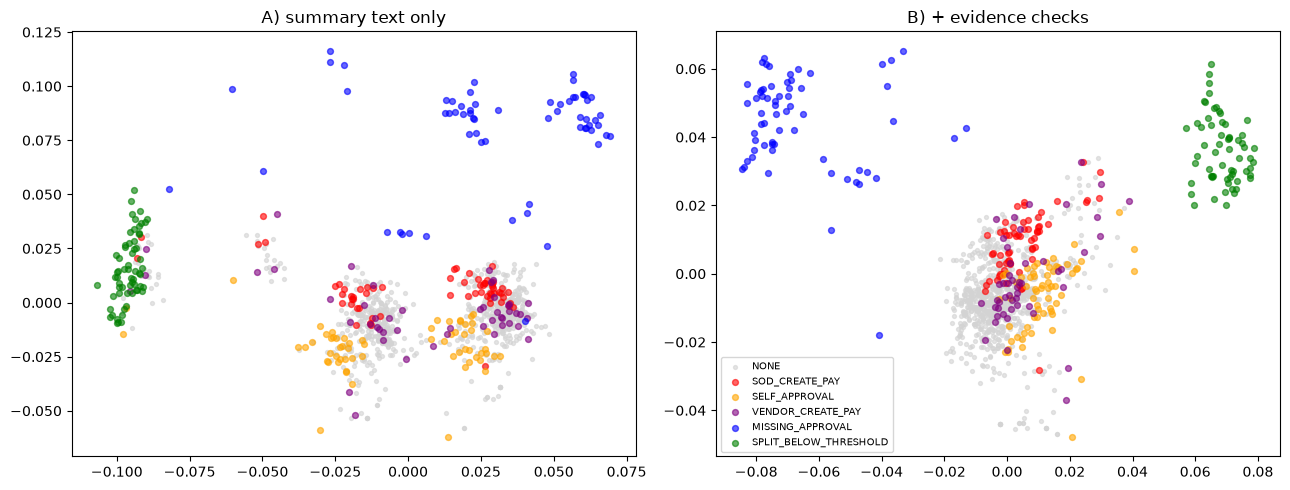

In [58]:
colors = {"NONE": "lightgrey", "SOD_CREATE_PAY": "red", "SELF_APPROVAL": "orange",
          "VENDOR_CREATE_PAY": "purple", "MISSING_APPROVAL": "blue", "SPLIT_BELOW_THRESHOLD": "green"}
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, xy, title in [(ax[0], xy1, "A) summary text only"), (ax[1], xy2, "B) + evidence checks")]:
    for t, c in colors.items():
        m = (samp.violation_type == t).values
        a.scatter(xy[m, 0], xy[m, 1], s=8 if t == "NONE" else 18, c=c, label=t, alpha=0.6)
    a.set_title(title)
ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig("../results/phase4_clusters.png", dpi=150)

## Phase 4 conclusion

**Retrieval.** Policy retrieval with normalised PO summaries returned the same three chunks for all 498 queries
(mean query-to-query cosine similarity 0.986): the summaries are near-identical templates, so the embedding
cannot discriminate between them. Z2 and Z3 are therefore invalid as RAG tests and are reported only for
transparency. Retrieval keyed on the model's own reason text works (5 distinct top-1 chunks, 89% agreement with
the predicted type, 79% hit@3 on true violations vs ~30% chance), but this measures consistency with the model's
claim, not correctness: a hallucinated claim gets a confident citation.

**What the rules do.** With the rules in the prompt the model caught [28]/[41] violations; without them [2]/[41].

**Why it over-flags** ([251] false alarms in Z0): [133] claimed SOD_CREATE_PAY with different user ids, [109]
claimed MISSING_APPROVAL where an Approved step exists (100% of those alarms), and the false-alarm rate is
[69]% when a conflict-role user is present vs [15]% when not.

**Stated facts are not enough.** Given computed checks (Z4), the model acted on the missing-approval check
(9/9) but on none of the same-user checks (0/29), so it moves from over-flagging to under-flagging.

**Embeddings.** 

A (text only): Most clusters are heavily mixed (violation shares mostly between 15% and 38%), with only MISSING_APPROVAL (Cluster 6) forming a pure 100% violation cluster, resulting in poor visual separation for the other violation types in the PCA plot.   

B (+ evidence checks): Injecting deterministic evidence perfectly isolates MISSING_APPROVAL (Cluster 4, 100% violations), SPLIT_BELOW_THRESHOLD (Cluster 2, 100% violations), and a massive block of normal POs (Cluster 3, 0% violations), pulling the blue and green dots into distinct, distant islands in the plot.   

**Data quality.** 3 of 498 dev POs matched the R5 definition but were generated as normal; labels were
corrected by rule before any test-set evaluation.

**Carried into Phase 5:** train on a balanced mix with hard negatives, a single `violation_type` output field,
and reasons that state the ids being compared.